===== Logistic Regression =====
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

===== Random Forest =====
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



,Model,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant)
0,Logistic Regression,0.9883,0.9844,0.9844,0.9844
1,Random Forest,0.9357,0.9206,0.9062,0.9134


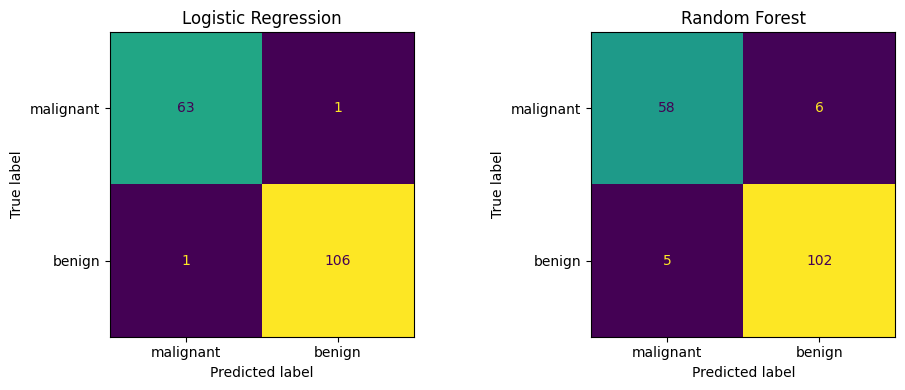

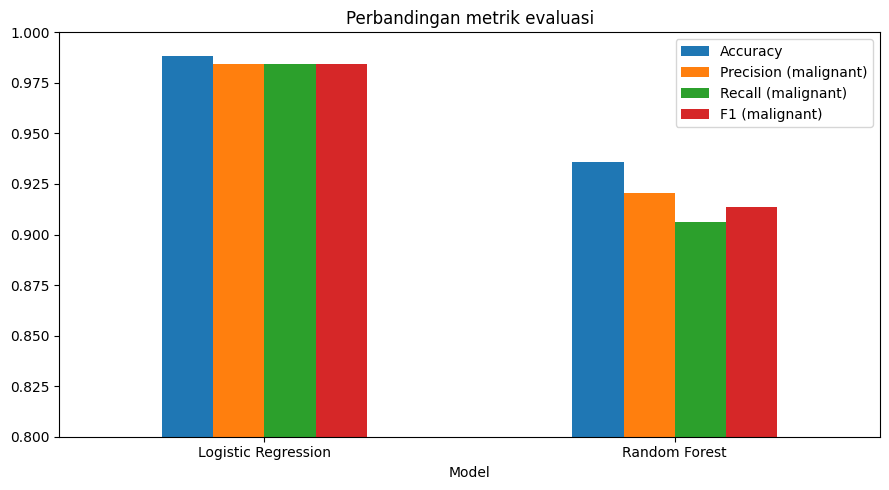

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

os.makedirs("results", exist_ok=True)

# 1. Data dan pembagian 70% training : 30% testing (sama untuk kedua model)
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# 2. Dua model
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

# 3. Training dan evaluasi (kelas positif = malignant, label 0)
rows, cms = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (malignant)": precision_score(y_test, y_pred, pos_label=0),
        "Recall (malignant)": recall_score(y_test, y_pred, pos_label=0),
        "F1 (malignant)": f1_score(y_test, y_pred, pos_label=0),
    })
    cms[name] = confusion_matrix(y_test, y_pred)
    print("=====", name, "=====")
    print(classification_report(y_test, y_pred, target_names=data.target_names))

results = pd.DataFrame(rows).round(4)
display(results)

# 4. Confusion matrix (disimpan sebagai gambar)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

# 5. Grafik perbandingan metrik (disimpan sebagai gambar)
results.set_index("Model").plot(kind="bar", figsize=(9, 5), ylim=(0.8, 1.0))
plt.title("Perbandingan metrik evaluasi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/evaluation_results.png", dpi=150)
plt.show()